## Reading data from parquet

In [1]:
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from pandas.core.tools.times import to_time

In [2]:
path = 'data/bitcoin_data.parquet'

In [3]:
data = pq.read_pandas(path)

In [4]:
data

pyarrow.Table
tx_id: string
conf_block_hash: string
found_at: timestamp[ns]
mined_at: timestamp[ns]
fee_rate_original: double
waittime: int64
weight_original: int64
size_original: int64
min_respend_blocks: int64
child_txid: string
rbf_fee_total: double
mempool_tx_count: double
mempool_size: double
total_output_amount: int64
absolute_fee_original: int64
weight: double
size: double
fee_rate: double
absolute_fee: double
vsize: double
has_corrected_weight: bool
label: string
n_in: int64
n_out: int64
has_op_return: int64
has_inscription: int64
block_height: int64
block_time: int64
block_tx_count: int64
block_total_weight: int64
block_median_feerate: double
block_p10_feerate: double
block_p90_feerate: double
time_since_last_block: double
gap_to_prev_block: double
ema_feerate_3block: double
is_cpfp_package: int64
found_at_ts: int64
epoch_id: int64
fee_rate_percentile: double
impatience: double
cumulative_weight: double
blockspace_utilization: double
log_weight: double
log_waittime: double
log

In [5]:
len(data)

11110277

# Opis kolumn

In [6]:
import json

In [7]:
json_path = 'data/bitcoin_data.metadata.json'

In [9]:
metadata = None
with open(json_path) as f:
    metadata = json.load(f)


In [10]:
metadata

{'description': 'Analysis-ready dataset for Bitcoin fee estimation (VCG two-stage structural model)',
 'exported_at': '2026-03-26T18:09:52.538437',
 'n_transactions': 11110277,
 'n_columns': 67,
 'n_epochs': 1988,
 'time_range': {'start': '2025-08-03 06:27:44', 'end': '2025-10-09 20:44:20'},
 'n_blocks': 5965,
 'build_params': {'db_path': '/home/armin/datalake/data-samples/11-24-2025-15m-data-lake.db',
  'annotation_path': '/home/armin/datalake/data-samples/tx-annotations-15m-2-7-2026.pkl',
  'mempool_space_db': '/home/kristian/notebooks/mempool_space_data.db',
  'block_limit': None,
  'epoch_mode': 'time',
  'epoch_duration_minutes': 30},
 'columns': {'tx_id': {'dtype': 'object',
   'description': 'Transaction ID (hex string)'},
  'conf_block_hash': {'dtype': 'object',
   'description': 'Block hash where transaction was confirmed'},
  'found_at': {'dtype': 'datetime64[ns]',
   'description': 'Timestamp when transaction was first seen in mempool'},
  'mined_at': {'dtype': 'datetime64[n

In [11]:
columns_info = metadata['columns']
columns_info

{'tx_id': {'dtype': 'object', 'description': 'Transaction ID (hex string)'},
 'conf_block_hash': {'dtype': 'object',
  'description': 'Block hash where transaction was confirmed'},
 'found_at': {'dtype': 'datetime64[ns]',
  'description': 'Timestamp when transaction was first seen in mempool'},
 'mined_at': {'dtype': 'datetime64[ns]',
  'description': 'Timestamp when transaction was confirmed in a block'},
 'fee_rate_original': {'dtype': 'float64',
  'description': 'Original fee rate from source database before correction'},
 'waittime': {'dtype': 'int64',
  'description': 'Seconds between first mempool observation and block confirmation'},
 'weight_original': {'dtype': 'int64',
  'description': 'Original weight from source database'},
 'size_original': {'dtype': 'int64',
  'description': 'Original size from source database'},
 'min_respend_blocks': {'dtype': 'int64',
  'description': 'Minimum blocks until any input can be re-spent (-1 if unknown)'},
 'child_txid': {'dtype': 'object',


In [13]:
columns_info['tx_id']['description']

'Transaction ID (hex string)'

In [52]:
for column, values in columns_info.items():
    description = values['description'] if 'description' in values else 'no description'
    print(f"{column}: {description}")


tx_id: Transaction ID (hex string)
conf_block_hash: Block hash where transaction was confirmed
found_at: Timestamp when transaction was first seen in mempool
mined_at: Timestamp when transaction was confirmed in a block
fee_rate_original: Original fee rate from source database before correction
waittime: Seconds between first mempool observation and block confirmation
weight_original: Original weight from source database
size_original: Original size from source database
min_respend_blocks: Minimum blocks until any input can be re-spent (-1 if unknown)
child_txid: CPFP child transaction ID (if this tx is a CPFP parent)
rbf_fee_total: Total fee paid via RBF replacement (if applicable)
mempool_tx_count: Number of transactions in mempool when tx was observed
mempool_size: Mempool size in bytes when tx was observed
total_output_amount: Total output value in satoshis
absolute_fee_original: Original fee from source database
weight: Transaction weight in WU (corrected; CPFP package weight for 

### Opis ważniejszych kolumn

W danych mamy aż 64 kolumny.

Na temat bloku w którym potwierdzono tranzakcje:
* **conf_block_hash** - numer bloku, w którym potwierdzono tranzakcje
* **block_time**: czas wykopania bloku
* **block_median_feerate**: Median fee rate in the confirmation block (sat/vB)
* **block_p10_feerate**: 10th percentile fee rate in the confirmation block
* **block_p90_feerate**: 90th percentile fee rate in the confirmation block


Czas:
* **found_at**: przybycie tranzakcji do mempoola (timestamp)
* **mined_at**: potwierdzenie tranzakcji (timestamp)
* **waittime**: różnica pomiędzy dwoma powyższymi czasami

Opłaty:
* **fee_rate_original**: Original fee rate from source database before correction
* **rbf_fee_total: Total**: fee paid via RBF replacement (if applicable)
* **absolute_fee_original**: Original fee from source database
*
Rozmiar
* **weight_original**: Original weight from source database
* **size_original**: Original size from source database
* **size**: Transaction size in bytes (corrected)
* **vsize**: Virtual size in vB (corrected; CPFP package vsize for parents)





# Czasy pojawiania się tranzakcji

In [24]:
arrival_times = data['found_at']
arrival_times

[
  [
    2025-09-09 21:40:57.000000000,
    2025-09-09 21:40:57.000000000,
    2025-09-09 21:40:57.000000000,
    2025-09-09 21:41:14.000000000,
    2025-09-09 21:41:14.000000000,
    ...
    2025-10-04 11:22:58.000000000,
    2025-10-04 11:22:58.000000000,
    2025-10-04 11:22:59.000000000,
    2025-10-04 11:22:59.000000000,
    2025-10-04 11:23:00.000000000
  ],
  [
    2025-10-04 11:23:00.000000000,
    2025-10-04 11:23:01.000000000,
    2025-10-04 11:23:04.000000000,
    2025-10-04 11:23:04.000000000,
    2025-10-04 11:23:04.000000000,
    ...
    2025-08-11 10:40:53.000000000,
    2025-08-11 10:40:53.000000000,
    2025-08-11 10:40:53.000000000,
    2025-08-11 10:40:53.000000000,
    2025-08-11 10:40:53.000000000
  ],
...,
  [
    2025-08-17 18:41:00.000000000,
    2025-08-17 18:41:00.000000000,
    2025-08-17 18:41:00.000000000,
    2025-08-17 18:41:00.000000000,
    2025-08-17 18:41:00.000000000,
    ...
    2025-08-15 18:02:09.000000000,
    2025-08-15 18:02:10.000000000,
    

In [41]:
type(arrival_times)

pyarrow.lib.ChunkedArray

In [42]:
type(arrival_times[0])

pyarrow.lib.TimestampScalar

## Zmiana na zwykłą tablice

In [43]:
arrival_times_normal =[]

In [48]:
testing_value = arrival_times[0]
testing_value

<pyarrow.TimestampScalar: '2025-09-09T21:40:57.000000000'>

In [49]:
to_timestamp = arrival_times[0].as_py()
to_timestamp

Timestamp('2025-09-09 21:40:57')

In [50]:
to_int = int(to_timestamp)

TypeError: int() argument must be a string, a bytes-like object or a real number, not 'Timestamp'

In [51]:
from datetime import datetime

curr = datetime.now()
curr

datetime.datetime(2026, 7, 9, 16, 7, 54, 272282)

In [ ]:
for i in arrival_times

In [27]:
diff = []
for i in range(1, len(arrival_times)):
    diff.append(arrival_times[i] - arrival_times[i-1])
diff


TypeError: int() argument must be a string, a bytes-like object or a real number, not 'pyarrow.lib.DurationScalar'

In [29]:
i = 0
t = arrival_times[i] - arrival_times[i-1]
t

<pyarrow.DurationScalar: Timedelta('36 days 23:46:48')>

In [31]:
t.as_py()

Timedelta('36 days 23:46:48')

In [37]:
l1 = arrival_times[i]
l1.as_py()

Timestamp('2025-09-09 21:40:57')

In [38]:
l2 = arrival_times[i+1]
l2.as_py()

Timestamp('2025-09-09 21:40:57')

In [40]:
l2.as_py() - l1.as_py()

Timedelta('0 days 00:00:00')

In [19]:
import matplotlib.pyplot as plt

TypeError: float() argument must be a string or a real number, not 'pyarrow.lib.DurationScalar'

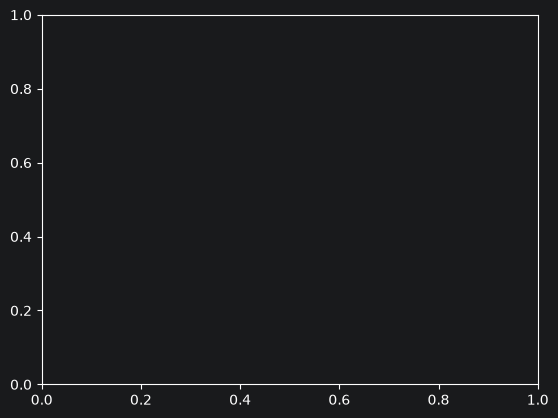

In [26]:
plt.plot(diff)
plt.show()